# 🐱 Purr-fectly Protected Qubits — the interactive cat notebook

*Companion notebook to the talk at **PushQuantum 2026** (Munich) by **Kerem Yurtseven** (TU Delft).*

| # | Section | What you will see |
|---|---|---|
| 1 | The Transmon | why a transmon is a qubit at all |
| 2 | What does a lost photon do? | Fock states vs coherent states |
| 3 | Initializing the Cat | turning the vacuum into a cat (Cochrane *et al.*, 1999) |
| 4 | QEC with Cats | counting qubits for error correction |
| 5 | Cat Qubit Stabilization | Kerr vs dissipative stabilization, and the bit-flip / phase-flip trade-off |
| 6 | Cat Qubit Control | Z gate, X gate, and what a photon does mid-gate |
| 7 | Bias-Preserving X | rotating phase space instead of dropping the walls |
| 8 | Bias-Preserving CX | a bias-preserving CX gate (Puri *et al.*, 2020) |

**Units.** We measure energies in units of the Kerr nonlinearity $K$ (or $\chi$) and times in units of $1/K$.
For a typical device with $K/2\pi = 3$ MHz, a time of $1/K$ is about 53 ns.

**Interactive cells.** Cells marked 🎛️ have sliders and play buttons. They appear when you run the cell (Jupyter, VS Code or Google Colab).

**Runtime.** The whole notebook runs in about one minute on a laptop or on Google Colab.

In [1]:
# On Google Colab (or anywhere qutip is missing) this installs it once.
try:
    import qutip
except ImportError:
    %pip install -q qutip
    import qutip
print("QuTiP", qutip.__version__)
try:
    import ipywidgets
except ImportError:
    %pip install -q ipywidgets

QuTiP 5.0.2


## 0. Setup

A few imports and small helpers that we reuse everywhere:

* `cat(alpha, sign)` builds the even ($+$) or odd ($-$) cat state $\mathcal N(|\alpha\rangle \pm |{-\alpha}\rangle)$.
* `logical(alpha)` returns the logical states $|0_L\rangle \approx |\alpha\rangle$ and $|1_L\rangle \approx |{-\alpha}\rangle$, built from the cats so that they are exactly orthogonal.
* `bloch(psi, alpha)` projects a state onto the cat qubit and returns its Bloch vector $(x, y, z)$ and the probability of being in the code space.
* `plot_wigner(ax, state)` draws a Wigner function with $x = \mathrm{Re}\,\beta$, $p = \mathrm{Im}\,\beta$, so a coherent state $|\alpha\rangle$ sits at $(\mathrm{Re}\,\alpha, \mathrm{Im}\,\alpha)$.

In [2]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

RED, BLUE, GREY, GOLD = "#9b2226", "#2f5d7c", "#8a8a8a", "#e0a800"
WCMAP = LinearSegmentedColormap.from_list("w", ["#14213d", "#3d6e8f", "#f7f3ea", "#c8553d", RED])
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
OPTS = {"nsteps": 500000, "atol": 1e-9, "rtol": 1e-7}      # ODE settings for stiff problems


def cat(N, alpha, sign=+1):
    # even (sign=+1) or odd (sign=-1) cat state  N(|alpha> + sign |-alpha>)
    return (qt.coherent(N, alpha) + sign * qt.coherent(N, -alpha)).unit()


def logical(N, alpha):
    # |0_L> ~ |alpha>, |1_L> ~ |-alpha>, exactly orthonormal
    cp, cm = cat(N, alpha, +1), cat(N, alpha, -1)
    return (cp + cm).unit(), (cp - cm).unit()


def bloch(psi, alpha):
    # Bloch vector (x, y, z) of the projection onto the cat qubit, and P(code space)
    N = psi.dims[0][0]
    z0, z1 = logical(N, alpha)
    rho = psi if psi.isoper else qt.ket2dm(psi)
    r00, r11 = qt.expect(rho, z0), qt.expect(rho, z1)
    r01 = z0.overlap(rho * z1)                          # <0_L| rho |1_L>
    return np.array([2 * r01.real, -2 * r01.imag, r00 - r11]), (r00 + r11).real


def plot_wigner(ax, state, title="", lim=3.2, n=161):
    x = np.linspace(-lim, lim, n)
    W = qt.wigner(state, x, x, g=2)                     # g=2  ->  axes are Re(beta), Im(beta)
    m = np.abs(W).max()
    ax.pcolormesh(x, x, W, cmap=WCMAP, norm=TwoSlopeNorm(0, -m, m), shading="auto", rasterized=True)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=11)
    ax.set_xlabel(r"Re $\beta$"); ax.set_ylabel(r"Im $\beta$")

### Helpers for the interactive cells 🎛️

* `wigner_grid(state)` computes the Wigner function on a fixed grid, and `show_wigner` draws it with one
  fixed colour scale, so frames can be compared.
* `show_landscape` draws a quasi-energy landscape $V(x)$ along $p = 0$ (blue), optional energy levels (grey),
  and the probability distribution of the field quadrature $x$ (red). That distribution is just the Wigner
  function integrated over $p$: $\;P(x) = \int W(x, p)\, dp$.
* `glider(draw, n_frames, ...)` makes a time slider with a ▶ button that calls `draw(k, ...)` for frame `k`.

In [3]:
import ipywidgets as widgets
from IPython.display import display

XS = np.linspace(-3.5, 3.5, 121)       # phase-space grid for the interactive plots
DX = XS[1] - XS[0]
WMAX = 2 / np.pi                        # largest possible |W|: one fixed colour scale for every frame


def wigner_grid(state):
    return qt.wigner(state, XS, XS, g=2)


def show_wigner(ax, W, title=""):
    ax.imshow(W, extent=[XS[0], XS[-1], XS[0], XS[-1]], origin="lower", cmap=WCMAP, vmin=-WMAX, vmax=WMAX)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(r"Re $\beta$"); ax.set_ylabel(r"Im $\beta$")


def show_landscape(ax, W, V, ymax, levels=()):
    P = W.sum(axis=0) * DX                          # integrate W over p  ->  P(x)
    ax.plot(XS, V, color=BLUE, lw=2)
    for E in levels:                                # a level is drawn where the landscape is below it
        ax.plot(XS, np.where(V <= E, E, np.nan), color=GREY, lw=1)
    h = 0.45 * ymax * P / 0.8                       # 0.8 = peak of P(x) for a coherent state
    ax.fill_between(XS, 0, h, color=RED, alpha=0.3, lw=0)
    ax.plot(XS, h, color=RED, lw=1.5)
    ax.set_xlim(XS[0], XS[-1]); ax.set_ylim(min(V.min(), 0) - 0.03 * ymax, ymax)
    ax.set_yticks([]); ax.set_xlabel(r"$x = \mathrm{Re}\,\beta$")


def glider(draw, n_frames, **controls):
    slider = widgets.IntSlider(value=0, min=0, max=n_frames - 1, description="time step")
    play = widgets.Play(value=0, min=0, max=n_frames - 1, interval=300)
    widgets.jslink((play, "value"), (slider, "value"))
    out = widgets.interactive_output(draw, {"k": slider, **controls})
    display(widgets.VBox([widgets.HBox([play, slider]), *controls.values()]), out)

## 1. The Transmon

A transmon is an **anharmonic oscillator**. Near the bottom of its potential it behaves like

$$\hat H = \omega_q\,\hat a^\dagger \hat a + \frac{\delta}{2}\,\hat a^{\dagger 2}\hat a^{2}, \qquad \delta < 0 .$$

The energies of the photon-number (Fock) states $|n\rangle$ follow line by line:

$$\hat a^{\dagger 2}\hat a^{2}\,|n\rangle = n(n-1)\,|n\rangle$$
$$E_n = \omega_q\, n + \frac{\delta}{2}\, n(n-1)$$
$$E_{n+1} - E_n = \omega_q + \delta\, n$$

So every step of the ladder is a little shorter than the one below. A microwave tone at $\omega_q$ only
talks to $|0\rangle \leftrightarrow |1\rangle$: those two rungs are the qubit
([Koch *et al.*, 2007](https://doi.org/10.1103/PhysRevA.76.042319)).

step sizes, harmonic : [5. 5. 5. 5.]
step sizes, transmon : [5.   4.75 4.5  4.25]   <- each step shorter by |delta|


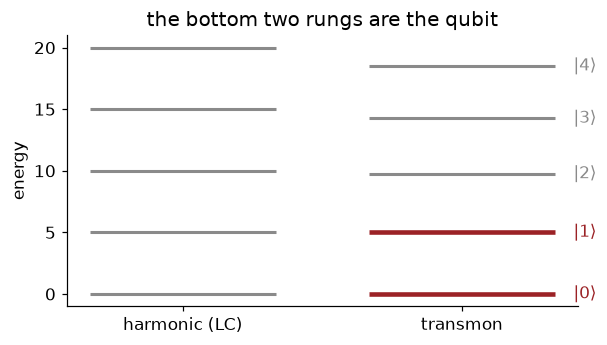

In [4]:
N = 8
a = qt.destroy(N)
wq, delta = 5.0, -0.25                       # GHz-like numbers (transmon: delta ~ -200..-300 MHz)

H_harm = wq * a.dag() * a
H_tr = wq * a.dag() * a + delta / 2 * a.dag()**2 * a**2

E_h, E_t = H_harm.eigenenergies()[:5], H_tr.eigenenergies()[:5]
print("step sizes, harmonic :", np.round(np.diff(E_h), 3))
print("step sizes, transmon :", np.round(np.diff(E_t), 3), "  <- each step shorter by |delta|")

fig, ax = plt.subplots(figsize=(6, 3.2))
for k in range(5):
    ax.hlines(E_h[k], 0, 1, color=GREY, lw=2)
    ax.hlines(E_t[k], 1.5, 2.5, color=RED if k < 2 else GREY, lw=3 if k < 2 else 2)
    ax.text(2.6, E_t[k], rf"$|{k}\rangle$", va="center", color=RED if k < 2 else GREY)
ax.set_xticks([0.5, 2]); ax.set_xticklabels(["harmonic (LC)", "transmon"]); ax.set_ylabel("energy")
ax.set_title("the bottom two rungs are the qubit")
plt.show()

## 2. What does a lost photon do?

The most common error in a superconducting circuit is **photon loss**. Mathematically, losing one photon
means applying the annihilation operator $\hat a$ to the state. Let us apply it to the two kinds of states
from the slides.

**Fock states (the transmon qubit):**

$$\hat a\,|1\rangle = |0\rangle \qquad\qquad \hat a\,|0\rangle = 0$$

A photon loss turns $|1\rangle$ into $|0\rangle$: a **bit flip**.

**Coherent states (the cat qubit):** a coherent state is an *eigenstate* of $\hat a$,

$$|\alpha\rangle = e^{-|\alpha|^2/2}\sum_n \frac{\alpha^n}{\sqrt{n!}}\,|n\rangle
\quad\Longrightarrow\quad
\hat a\,|\alpha\rangle = \alpha\,|\alpha\rangle, \qquad \hat a\,|{-\alpha}\rangle = -\alpha\,|{-\alpha}\rangle .$$

A lost photon leaves $|\pm\alpha\rangle$ where they are and only multiplies them by $\pm\alpha$.
With $|0_L\rangle = |\alpha\rangle$ and $|1_L\rangle = |{-\alpha}\rangle$, that is a **sign**, i.e. a **phase flip**.

We can check this by writing $\hat a$ as a $2\times 2$ matrix in each qubit basis:

In [5]:
# transmon qubit: basis {|0>, |1>}
N = 2
a2 = qt.destroy(N)
print("transmon:  <i| a |j> =\n", np.round(a2.full().real, 3), "\n  -> |1> goes to |0>: a bit flip")

# cat qubit: basis {|0_L>, |1_L>} with alpha = 2
N, alpha = 30, 2.0
a = qt.destroy(N)
z0, z1 = logical(N, alpha)
M = np.array([[zi.overlap(a * zj) for zj in (z0, z1)] for zi in (z0, z1)]) / alpha
print("\ncat (divided by alpha):  <i_L| a |j_L> / alpha =\n", np.round(M.real, 3),
      "\n  -> diag(+1, -1) = Pauli Z: only a phase flip")

transmon:  <i| a |j> =
 [[0. 1.]
 [0. 0.]] 
  -> |1> goes to |0>: a bit flip

cat (divided by alpha):  <i_L| a |j_L> / alpha =
 [[ 1. -0.]
 [ 0. -1.]] 
  -> diag(+1, -1) = Pauli Z: only a phase flip


A picture says the same thing. The **Wigner function** of the even cat $|C^+\rangle$ has two blobs (the two
logical states) and interference fringes between them (their relative phase). After a photon loss the blobs
are untouched, but the fringes flip sign: the even cat has become the odd cat $|C^-\rangle$.

$$
|C^\pm\rangle = \frac{|\alpha\rangle \pm |-\alpha\rangle}{\sqrt{2}}
$$

overlap of a|C+> with |C->  : 1.0


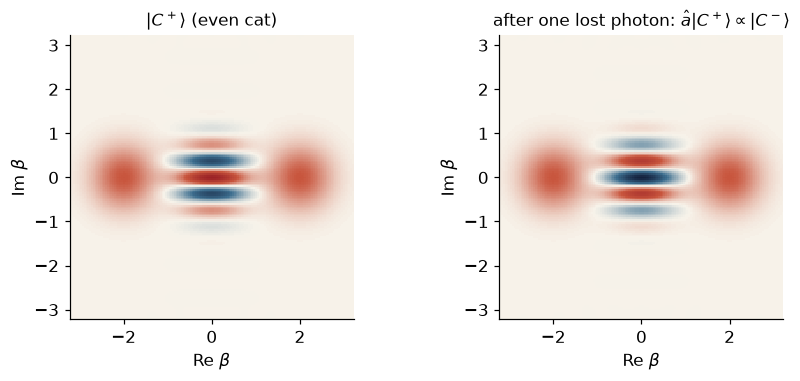

In [6]:
N, alpha = 30, 2.0
a = qt.destroy(N)
even = cat(N, alpha, +1)
after = (a * even).unit()
print("overlap of a|C+> with |C->  :", round(abs(cat(N, alpha, -1).overlap(after))**2, 6))

fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
plot_wigner(ax[0], even, r"$|C^+\rangle$ (even cat)")
plot_wigner(ax[1], after, r"after one lost photon: $\hat a|C^+\rangle \propto |C^-\rangle$")
plt.tight_layout(); plt.show()

For comparison, here is a transmon in $|+\rangle = (|0\rangle + |1\rangle)/\sqrt2$ losing energy at rate $\gamma$
(master equation with collapse operator $\sqrt{\gamma}\,\hat a$). Both the population of $|1\rangle$
(bit information) and the coherence $|\rho_{01}|$ (phase information) decay:

$$P_1(t) = \tfrac12 e^{-\gamma t}, \qquad |\rho_{01}(t)| = \tfrac12 e^{-\gamma t/2}.$$

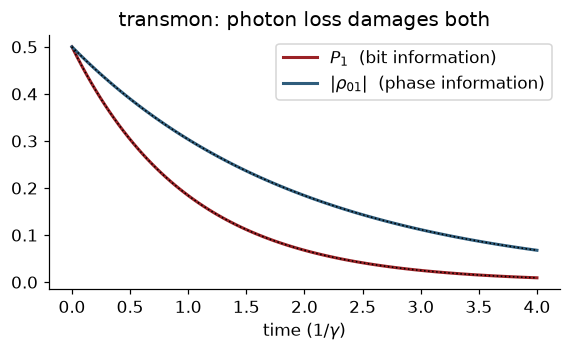

In [7]:
gamma = 1.0
t = np.linspace(0, 4, 100)
plus = (qt.basis(2, 0) + qt.basis(2, 1)).unit()
res = qt.mesolve(qt.qzero(2), plus, t, c_ops=[np.sqrt(gamma) * qt.destroy(2)])
P1 = [s[1, 1].real for s in res.states]
coh = [abs(s[0, 1]) for s in res.states]

plt.figure(figsize=(6, 3))
plt.plot(t, P1, color=RED, lw=2, label=r"$P_1$  (bit information)")
plt.plot(t, coh, color=BLUE, lw=2, label=r"$|\rho_{01}|$  (phase information)")
plt.plot(t, 0.5 * np.exp(-gamma * t), "k:", lw=1); plt.plot(t, 0.5 * np.exp(-gamma * t / 2), "k:", lw=1)
plt.xlabel(r"time ($1/\gamma$)"); plt.legend(); plt.title("transmon: photon loss damages both")
plt.show()

## 3. Initializing The Cat

### Far apart means safe

The two logical states $|\pm\alpha\rangle$ are **far apart** in phase space. Their overlap shrinks
exponentially with the mean photon number $|\alpha|^2$:

$$\langle \alpha | {-\alpha} \rangle = e^{-2|\alpha|^2} \qquad\Longrightarrow\qquad |\langle \alpha | {-\alpha} \rangle|^2 = e^{-4|\alpha|^2}.$$

In [8]:
for n in [1, 2, 4, 6, 10]:
    print(f"|alpha|^2 = {n:2d}:   |<alpha|-alpha>|^2 = {np.exp(-4 * n):.1e}")

|alpha|^2 =  1:   |<alpha|-alpha>|^2 = 1.8e-02
|alpha|^2 =  2:   |<alpha|-alpha>|^2 = 3.4e-04
|alpha|^2 =  4:   |<alpha|-alpha>|^2 = 1.1e-07
|alpha|^2 =  6:   |<alpha|-alpha>|^2 = 3.8e-11
|alpha|^2 = 10:   |<alpha|-alpha>|^2 = 4.2e-18


### Making a cat from the vacuum (Cochrane, Milburn & Munro, 1999)

[Cochrane *et al.*](https://doi.org/10.1103/PhysRevA.59.2631) proposed this Hamiltonian, which is a Kerr
term plus a two-photon drive:

$$\hat H_C = \chi\,\hat a^{\dagger 2}\hat a^{2} - \kappa\,(\hat a^{2} + \hat a^{\dagger 2}).$$

It can be rewritten as a perfect square. Expanding the product, line by line:

$$\chi(\hat a^{\dagger 2} - \alpha^2)(\hat a^{2} - \alpha^2)
= \chi\,\hat a^{\dagger 2}\hat a^{2} - \chi\alpha^2(\hat a^{2} + \hat a^{\dagger 2}) + \chi\alpha^4$$
$$\Longrightarrow\quad \hat H_C = \chi(\hat a^{\dagger 2} - \alpha^2)(\hat a^{2} - \alpha^2) - \chi\alpha^4,
\qquad \alpha^2 = \kappa/\chi .$$

Because $(\hat a^2 - \alpha^2)|\pm\alpha\rangle = 0$, both $|\alpha\rangle$ and $|{-\alpha}\rangle$ are
**degenerate ground states**. Replacing $\hat a$ by a complex number $\beta = x + ip$ gives the classical
"landscape" $\chi|\beta^2 - \alpha^2|^2$: two valleys at $\pm\alpha$ with a barrier in between.

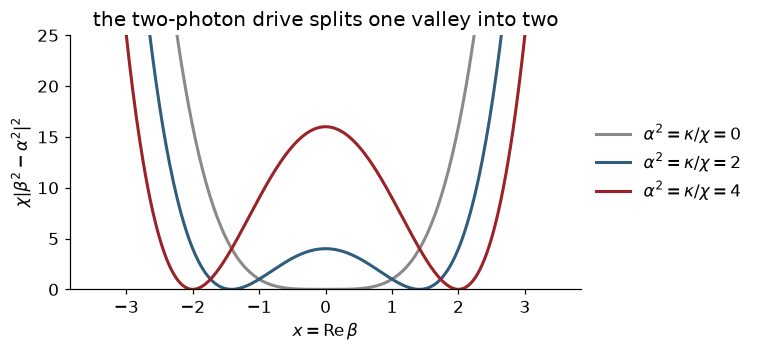

In [9]:
x = np.linspace(-3.5, 3.5, 400)
fig, ax = plt.subplots(figsize=(6, 3))
for A2, c in [(0, GREY), (2, BLUE), (4, RED)]:
    ax.plot(x, (x**2 - A2)**2, color=c, lw=2, label=rf"$\alpha^2 = \kappa/\chi = {A2}$")
ax.set_ylim(0, 25); ax.set_xlabel(r"$x = \mathrm{Re}\,\beta$"); ax.set_ylabel(r"$\chi|\beta^2-\alpha^2|^2$")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.set_title("the two-photon drive splits one valley into two"); plt.show()

### 🎛️ Try it: grow the cat

Change the cat size $|\alpha|^2 = \kappa/\chi$ and pick a state. Left: the landscape, the energy levels of
$\hat H_C$ (grey) and $P(x)$ of the state (red). Right: its Wigner function. Things to notice:

* the two cats $|C^\pm\rangle$ always sit at exactly zero energy, at the bottom of the valleys;
* the gap to the next level grows with the cat (towards $\approx 4\chi|\alpha|^2$ for big cats), which is what protects it;
* for a small cat, $|0_L\rangle$ and $|1_L\rangle$ are not two separate blobs at all. Protection needs the valleys to be far apart.

In [ ]:
N_sw = 40
a_sw = qt.destroy(N_sw)

def draw_alpha(A2, state):
    alpha = np.sqrt(A2)
    levels = ((a_sw.dag()**2 - A2) * (a_sw**2 - A2)).eigenenergies()[:14]     # H_C + chi*alpha^4
    z0, z1 = logical(N_sw, alpha)
    psi = {"C+": cat(N_sw, alpha, +1), "C-": cat(N_sw, alpha, -1), "0L": z0, "1L": z1}[state]
    W = wigner_grid(psi)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1]))
    show_landscape(ax[0], W, (XS**2 - A2)**2, ymax=40, levels=levels[2:])
    ax[0].set_title(rf"gap to the next level = {levels[2]:.1f}$\,\chi$   ($4|\alpha|^2\chi$ = {4 * A2:.1f})",
                    fontsize=10)
    show_wigner(ax[1], W, rf"overlap $|\langle\alpha|{{-\alpha}}\rangle|^2$ = {np.exp(-4 * A2):.1e}")
    plt.tight_layout(); plt.show()

widgets.interact(draw_alpha,
                 A2=widgets.FloatSlider(value=2.0, min=0.1, max=6.0, step=0.1, description="|α|²"),
                 state=widgets.ToggleButtons(style={"button_width": "auto"}, options=[("even cat", "C+"), ("odd cat", "C-"),
                                                      ("|0_L⟩", "0L"), ("|1_L⟩", "1L")]));

interactive(children=(FloatSlider(value=2.0, description='|α|²', max=6.0, min=0.1), ToggleButtons(description=…

Now the recipe from the paper: start in the vacuum $|0\rangle$ (the ground state of $\chi\,\hat a^{\dagger 2}\hat a^2$)
and slowly turn on the drive, $\kappa(t) = \kappa_0 \tanh^2(\lambda t)$. If the ramp is slow enough
(adiabatic), the state follows the ground state. $\hat H_C$ never changes the photon-number parity, so the
even vacuum must end in the **even** ground state:

$$|0\rangle \;\longrightarrow\; |C^+\rangle = \tfrac{1}{\sqrt2}\big(|0_L\rangle + |1_L\rangle\big).$$

Try different ramp speeds $\lambda$: faster ramps leave the ground state.

ramp speed lambda = 1.20:  fidelity with the even cat = 0.528
ramp speed lambda = 0.60:  fidelity with the even cat = 0.780
ramp speed lambda = 0.30:  fidelity with the even cat = 0.955
ramp speed lambda = 0.15:  fidelity with the even cat = 0.999


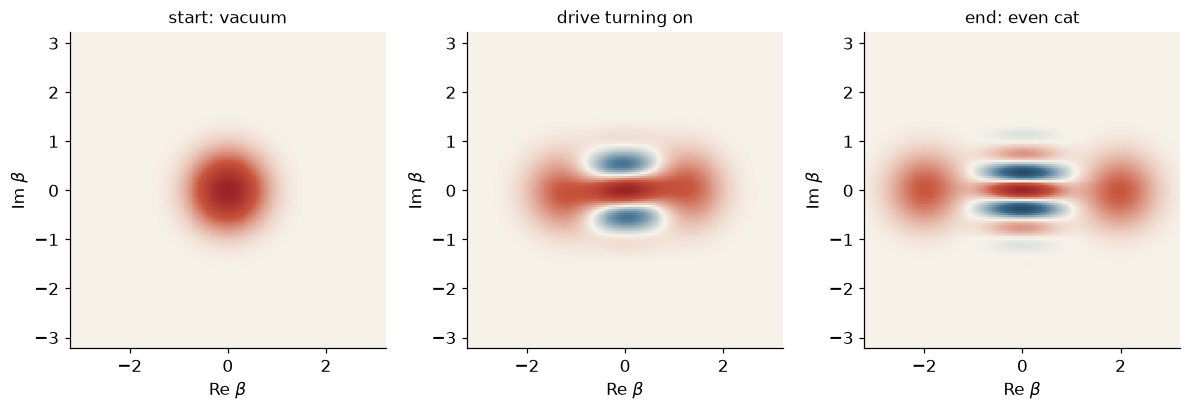

In [11]:
N, chi, A2 = 30, 1.0, 4.0
a = qt.destroy(N)
target = cat(N, np.sqrt(A2), +1)

def ramp(lam, n_t=150):
    T = 6 / lam
    H = [chi * a.dag()**2 * a**2,
         [-(a**2 + a.dag()**2), lambda t: chi * A2 * np.tanh(lam * t)**2]]
    return qt.sesolve(H, qt.basis(N, 0), np.linspace(0, T, n_t), options=OPTS)

for lam in [1.2, 0.6, 0.3, 0.15]:
    psi = ramp(lam).states[-1]
    print(f"ramp speed lambda = {lam:4.2f}:  fidelity with the even cat = {abs(target.overlap(psi))**2:.3f}")

res = ramp(0.15)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for axi, k, lab in zip(ax, [0, 18, -1], ["start: vacuum", "drive turning on", "end: even cat"]):
    plot_wigner(axi, res.states[k], lab)
plt.tight_layout(); plt.show()

### 🎛️ Watch it: the ramp, frame by frame

Press ▶ or drag the slider. Compare the slow ramp with the fast one: the fast ramp leaves the ground state,
so the final state is not the even cat.

In [ ]:
ramp_runs = {0.15: res, 0.6: ramp(0.6)}           # slow ramp (computed above) and a fast one
ramp_A2, ramp_target = A2, target

def draw_ramp(k, lam):
    r = ramp_runs[lam]
    i = round(k * (len(r.times) - 1) / 60)
    t, psi = r.times[i], r.states[i]
    s = ramp_A2 * np.tanh(lam * t)**2                # kappa(t)/chi = the current |alpha|^2
    W = wigner_grid(psi)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1]))
    show_landscape(ax[0], W, (XS**2 - s)**2, ymax=30)
    ax[0].set_title(rf"$t = {t:.1f}/\chi$,   $\kappa(t)/\chi = {s:.2f}$", fontsize=10)
    show_wigner(ax[1], W, f"fidelity with the even cat: {abs(ramp_target.overlap(psi))**2:.3f}")
    plt.tight_layout(); plt.show()

glider(draw_ramp, 61, lam=widgets.ToggleButtons(style={"button_width": "auto"}, options=[("slow ramp", 0.15), ("fast ramp", 0.6)]))

Output()

## 4. QEC with Cats

A transmon suffers **both** bit flips and phase flips, so it needs a 2D code. The rotated
**surface code** of distance $d$ uses

$$n_\text{surface} = d^2 \;(\text{data}) + d^2 - 1 \;(\text{measure}) = 2d^2 - 1 \text{ qubits.}$$

A cat only suffers phase flips, so a 1D **repetition code** is enough
([Guillaud & Mirrahimi, 2019](https://doi.org/10.1103/PhysRevX.9.041053)):

$$n_\text{repetition} = d \;(\text{data}) + d - 1 \;(\text{ancilla}) = 2d - 1 \text{ qubits.}$$

Below threshold, the logical error per cycle falls roughly as
([Fowler *et al.*, 2012](https://doi.org/10.1103/PhysRevA.86.032324))

$$\varepsilon_L \approx 0.1\left(\frac{p}{p_\text{th}}\right)^{(d+1)/2}.$$

Assume both codes run 10× below their threshold ($p/p_\text{th} = 0.1$) and that cat bit flips are
negligible. Then both need the **same** distance $d$ for the same target; only the cost per distance differs.

  target |   d | transmons (2d^2-1) | cats (2d-1)
   1e-06 |   9 |                161 |          17
   1e-09 |  15 |                449 |          29
   1e-12 |  21 |                881 |          41


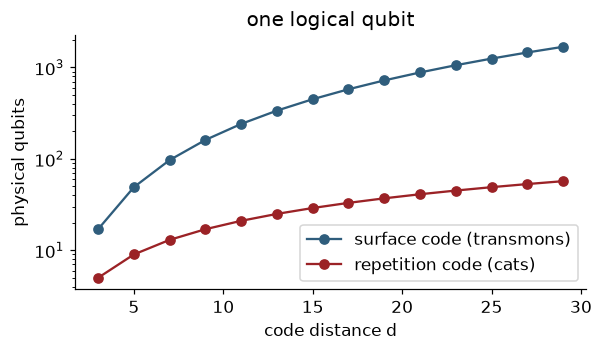

In [13]:
def distance_needed(target, ratio=0.1):
    d = 3
    while 0.1 * ratio**((d + 1) / 2) > target * (1 + 1e-9):   # tolerance for rounding
        d += 2
    return d

print(f"{'target':>8} | {'d':>3} | {'transmons (2d^2-1)':>18} | {'cats (2d-1)':>11}")
for target in [1e-6, 1e-9, 1e-12]:
    d = distance_needed(target)
    print(f"{target:8.0e} | {d:3d} | {2*d*d - 1:18d} | {2*d - 1:11d}")

d = np.arange(3, 31, 2)
plt.figure(figsize=(6, 3))
plt.semilogy(d, 2 * d**2 - 1, "o-", color=BLUE, label="surface code (transmons)")
plt.semilogy(d, 2 * d - 1, "o-", color=RED, label="repetition code (cats)")
plt.xlabel("code distance d"); plt.ylabel("physical qubits"); plt.legend()
plt.title("one logical qubit"); plt.show()

For reference: Google's Willow chip ran a $d=7$ surface code with 97 qubits (plus 4 for leakage removal)
([Google Quantum AI, 2025](https://doi.org/10.1038/s41586-024-08449-y)), and AWS's Ocelot chip ran a
$d=5$ repetition cat code with 5 cats and 4 transmon ancillas
([Putterman *et al.*, 2025](https://doi.org/10.1038/s41586-025-08642-7)).

### 🎛️ Try it: how many qubits for one logical qubit?

Choose how far below threshold the hardware runs ($p/p_\text{th}$) and the logical error you need. Blue: a
surface code of transmons ($2d^2 - 1$). Red and grey: a repetition code of cats and ancillas ($2d - 1$),
drawn with the same spacing.

In [ ]:
def draw_qec(ratio, log_target):
    d = distance_needed(10.0**log_target, ratio)
    s = min((100 / (d + 1))**2, 300)                       # marker size
    fig, ax = plt.subplots(figsize=(10, 4.2))
    i, j = np.meshgrid(np.arange(d), np.arange(d))          # data qubits
    ax.scatter(i, j, s=s, color=BLUE, lw=0)
    mi, mj = np.meshgrid(np.arange(d - 1) + 0.5, np.arange(d - 1) + 0.5)   # measure qubits, inside
    edge = np.arange(d - 1) + 0.5
    mx = np.concatenate([mi.ravel(), edge[::2], edge[1::2], np.full((d - 1) // 2, -0.5), np.full((d - 1) // 2, d - 0.5)])
    my = np.concatenate([mj.ravel(), np.full((d - 1) // 2, d - 0.5), np.full((d - 1) // 2, -0.5), edge[1::2], edge[::2]])
    ax.scatter(mx, my, s=s, color=BLUE, alpha=0.35, lw=0)
    line = np.arange(2 * d - 1) * 0.5                        # cats (even sites) and ancillas (odd sites)
    ax.scatter(line, np.full_like(line, -1.5), s=max(s, 6), color=[RED if n % 2 == 0 else GREY for n in range(2 * d - 1)], lw=0)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"d = {d}:   {2 * d * d - 1} transmons (blue)   vs   {2 * d - 1} cat-code qubits (red + grey)",
                 fontsize=11)
    plt.show()

widgets.interact(draw_qec,
                 ratio=widgets.FloatSlider(value=0.1, min=0.02, max=0.3, step=0.01, description="p / p_th"),
                 log_target=widgets.IntSlider(value=-12, min=-15, max=-3, description="log₁₀ target"));

interactive(children=(FloatSlider(value=0.1, description='p / p_th', max=0.3, min=0.02, step=0.01), IntSlider(…

## 5. Cat Qubit Stabilization

### Left alone, the cat shrinks

Photon loss has two parts. A **jump** applies $\hat a$, which we saw is harmless. But when *no* photon is
detected, the state is also updated, by $e^{-\kappa_1 t\,\hat a^\dagger\hat a/2}$. On a coherent state:

$$e^{-\kappa_1 t\,\hat a^\dagger\hat a/2}\,|\alpha\rangle
\;\propto\; \sum_n \frac{(\alpha e^{-\kappa_1 t/2})^n}{\sqrt{n!}}\,|n\rangle
\;\propto\; |\alpha\, e^{-\kappa_1 t/2}\rangle .$$

Both cats slide toward the origin, their overlap grows, and the protection disappears. We need something
that keeps pushing them back out to $\pm\alpha$. There are two ways:

* **Kerr cat** (the "moat"): keep the Hamiltonian on, $\hat H = -K\hat a^{\dagger 2}\hat a^{2} + \epsilon_2(\hat a^{\dagger 2} + \hat a^{2})$, with $\alpha^2 = \epsilon_2/K$
  ([Puri, Boutin & Blais, 2017](https://doi.org/10.1038/s41534-017-0019-1); [Grimm *et al.*, 2020](https://doi.org/10.1038/s41586-020-2587-z)).
  This is $-\hat H_C$ from above: same physics, opposite sign convention.
* **Dissipative cat** (the "keeper"): engineer a loss that removes photons *in pairs*, $\hat L_2 = \sqrt{\kappa_2}\,(\hat a^{2} - \alpha^{2})$
  ([Mirrahimi *et al.*, 2014](https://doi.org/10.1088/1367-2630/16/4/045014); [Leghtas *et al.*, 2015](https://doi.org/10.1126/science.aaa2085)).
  Since $\hat L_2|\pm\alpha\rangle = 0$, the cats are left alone and everything else is pumped back.

Let us run all three with the same single-photon loss $\kappa_1$:

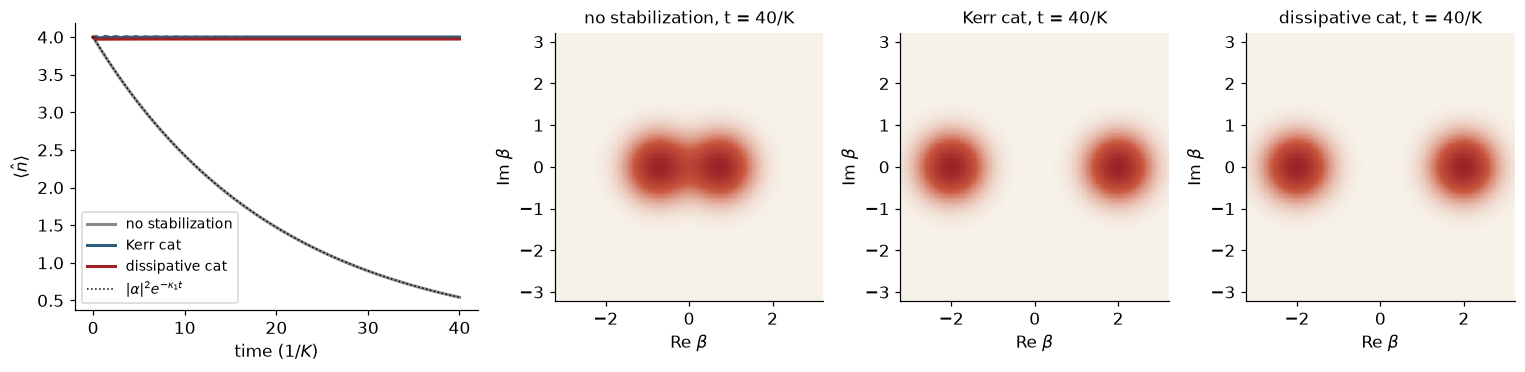

In [15]:
N, A2, k1 = 30, 4.0, 0.05                     # units of K (= kappa_2)
a = qt.destroy(N)
psi0 = cat(N, np.sqrt(A2), +1)
t = np.linspace(0, 40, 121)
loss = [np.sqrt(k1) * a]

cases = {
    "no stabilization": (qt.qzero(N), loss),
    "Kerr cat":         (-a.dag()**2 * a**2 + A2 * (a.dag()**2 + a**2), loss),
    "dissipative cat":  (qt.qzero(N), loss + [a**2 - A2]),
}
results = {name: qt.mesolve(H, psi0, t, c_ops=c, e_ops=[a.dag() * a], options=OPTS)
           for name, (H, c) in cases.items()}

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4), gridspec_kw=dict(width_ratios=[1.5, 1, 1, 1]))
for (name, r), col in zip(results.items(), [GREY, BLUE, RED]):
    ax[0].plot(t, r.expect[0], color=col, lw=2, label=name)
ax[0].plot(t, A2 * np.exp(-k1 * t), "k:", lw=1, label=r"$|\alpha|^2 e^{-\kappa_1 t}$")
ax[0].set_xlabel(r"time ($1/K$)"); ax[0].set_ylabel(r"$\langle \hat n \rangle$"); ax[0].legend(fontsize=9)
for axi, (name, (H, c)) in zip(ax[1:], cases.items()):
    final = qt.mesolve(H, psi0, [0, t[-1]], c_ops=c, options=OPTS).states[-1]
    plot_wigner(axi, final, f"{name}, t = {t[-1]:.0f}/K")
plt.tight_layout(); plt.show()

The free cat shrinks to the origin. Both stabilized cats keep their size; the blobs survive, only the
fringes fade (phase flips still happen, as expected).

### The trade-off: bit flips vs phase flips

How long does a stabilized cat keep its bit, and how long its phase? Both lifetimes are hidden in the
**Lindbladian** $\mathcal L$, the superoperator that generates $\dot\rho = \mathcal L\rho$. Its eigenvalues
$\lambda_k$ are decay rates. One is $0$ (the steady state); the next slowest are the qubit's error rates:

* the **bit-flip rate**: how fast population leaks between $|\alpha\rangle$ and $|{-\alpha}\rangle$,
* the **phase-flip rate**: how fast the coherence between them decays, expected to be $\approx 2\kappa_1|\alpha|^2$.

For a dissipative cat, the bit-flip rate is predicted to fall roughly like $e^{-2|\alpha|^2}$
([Mirrahimi *et al.*, 2014](https://doi.org/10.1088/1367-2630/16/4/045014); measured by
[Lescanne *et al.*, 2020](https://doi.org/10.1038/s41567-020-0824-x)).

### 🎛️ Watch it: shrinking vs stabilized cats

Same simulation, now frame by frame. The blue curve is the cat size, $\langle\hat n\rangle/|\alpha|^2$. The red
curve is the photon-number parity $\langle e^{i\pi\hat n}\rangle$, which is what the fringes encode: $+1$ for
the even cat. Every lost photon flips the parity, so its decay is the phase-flip error. Stabilization keeps
the size, not the parity. (The free cat's parity creeps back up only because it ends in the vacuum, which is even.)

In [16]:
st_t = np.linspace(0, 30, 41)
st_a, st_A2 = a, A2
parity = (1j * np.pi * st_a.dag() * st_a).expm()
st_runs = {name: qt.mesolve(H, psi0, st_t, c_ops=c, options=OPTS).states for name, (H, c) in cases.items()}
st_size = {name: qt.expect(st_a.dag() * st_a, s) / st_A2 for name, s in st_runs.items()}
st_par = {name: qt.expect(parity, s) for name, s in st_runs.items()}

def draw_stab(k, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1]))
    ax[0].plot(st_t, st_size[name], color=BLUE, lw=2, label=r"size $\langle\hat n\rangle/|\alpha|^2$")
    ax[0].plot(st_t, st_par[name], color=RED, lw=2, label=r"parity $\langle e^{i\pi\hat n}\rangle$")
    ax[0].plot(st_t[k], st_size[name][k], "o", color=BLUE, ms=8)
    ax[0].plot(st_t[k], st_par[name][k], "o", color=RED, ms=8)
    ax[0].set_ylim(-0.05, 1.1); ax[0].set_xlabel(r"time ($1/K$)"); ax[0].legend(fontsize=9)
    show_wigner(ax[1], wigner_grid(st_runs[name][k]), f"{name},  t = {st_t[k]:.1f}/K")
    plt.tight_layout(); plt.show()

glider(draw_stab, len(st_t), name=widgets.ToggleButtons(style={"button_width": "auto"}, options=list(cases)))

Output()

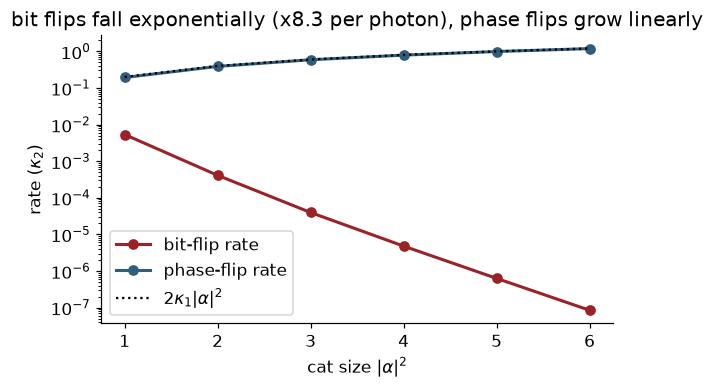

In [17]:
k1 = 0.1                                       # single-photon loss, in units of kappa_2
sizes = np.arange(1, 7)
bit, phase = [], []
for A2 in sizes:
    N = 32
    a = qt.destroy(N)
    L = qt.liouvillian(qt.qzero(N), [a**2 - A2, np.sqrt(k1) * a])
    ev = np.sort(-np.linalg.eigvals(L.full()).real)     # decay rates, smallest first
    bit.append(ev[1]); phase.append(ev[2])

slope = np.polyfit(sizes[1:], np.log(bit[1:]), 1)[0]
plt.figure(figsize=(6, 3.4))
plt.semilogy(sizes, bit, "o-", color=RED, lw=2, label="bit-flip rate")
plt.semilogy(sizes, phase, "o-", color=BLUE, lw=2, label="phase-flip rate")
plt.semilogy(sizes, 2 * k1 * sizes, "k:", label=r"$2\kappa_1|\alpha|^2$")
plt.xlabel(r"cat size $|\alpha|^2$"); plt.ylabel(r"rate ($\kappa_2$)"); plt.legend()
plt.title(f"bit flips fall exponentially (x{np.exp(-slope):.1f} per photon), phase flips grow linearly")
plt.show()

This is the whole idea of cat qubits in one plot: make the cat bigger, and bit flips disappear exponentially
while phase flips only grow linearly. The remaining phase flips are what the repetition code in Section 4
corrects. (Real devices also have thermal noise and other imperfections, which put a floor under the
bit-flip rate; a dissipative cat has already reached bit-flip times above 10 seconds,
[Réglade *et al.*, 2024](https://doi.org/10.1038/s41586-024-07294-3).)

## 6. Cat Qubit Control

From here on we use the **Kerr cat** with $K = 1$ and $\alpha^2 = \epsilon_2/K = 4$.
These gates were first demonstrated by [Grimm *et al.*, 2020](https://doi.org/10.1038/s41586-020-2587-z).

> ⚠️ Grimm *et al.* label the cats $|C^\pm\rangle$ as the $Z$ axis. We use $|0_L\rangle = |\alpha\rangle$,
> so their "X rotation" is our Z rotation and vice versa.

### Z gate: tilt the landscape

Add a weak drive at the cat frequency, $\epsilon_x(\hat a + \hat a^\dagger)$. Its energy on each logical state:

$$\langle \pm\alpha|\,\epsilon_x(\hat a + \hat a^\dagger)\,|\pm\alpha\rangle = \pm 2\epsilon_x\alpha$$
$$\Delta E = 4\epsilon_x\alpha \quad\Longrightarrow\quad \text{relative phase } \varphi(t) = 4\epsilon_x\alpha\, t .$$

One valley sinks, the other rises, and the phase between them winds: a rotation about Z. The cats never leave
their valleys, so this gate keeps the bias.

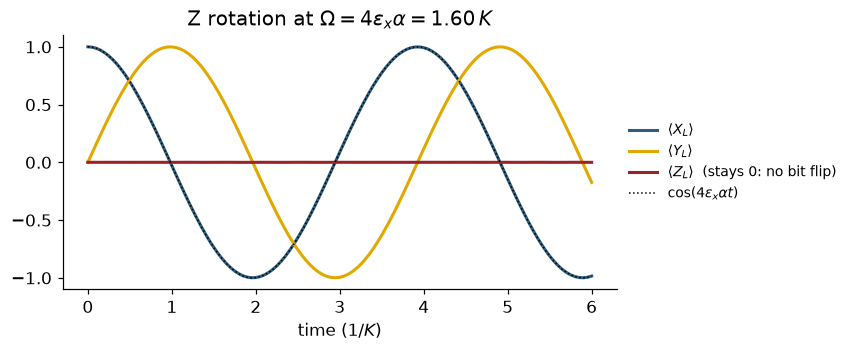

In [18]:
N, A2, eps_x = 30, 4.0, 0.2
alpha = np.sqrt(A2)
a = qt.destroy(N)
H = -a.dag()**2 * a**2 + A2 * (a.dag()**2 + a**2) + eps_x * (a + a.dag())
t = np.linspace(0, 6, 121)
res = qt.sesolve(H, cat(N, alpha, +1), t, options=OPTS)        # start in |+> = even cat
B = np.array([bloch(s, alpha)[0] for s in res.states])

Omega = 4 * eps_x * alpha
plt.figure(figsize=(6.5, 3))
plt.plot(t, B[:, 0], color=BLUE, lw=2, label=r"$\langle X_L\rangle$")
plt.plot(t, B[:, 1], color=GOLD, lw=2, label=r"$\langle Y_L\rangle$")
plt.plot(t, B[:, 2], color=RED, lw=2, label=r"$\langle Z_L\rangle$  (stays 0: no bit flip)")
plt.plot(t, np.cos(Omega * t), "k:", lw=1, label=r"$\cos(4\epsilon_x\alpha t)$")
plt.xlabel(r"time ($1/K$)"); plt.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.title(rf"Z rotation at $\Omega = 4\epsilon_x\alpha = {Omega:.2f}\,K$"); plt.show()

### 🎛️ Watch it: the Z gate

The drive tilts the landscape a little, so the $|0_L\rangle$ valley sits lower than the $|1_L\rangle$ valley.
The blobs never move; only the fringes slide, because the relative phase between the blobs winds. On the
Bloch sphere the state circles around the equator.

In [19]:
z_res, z_B, z_t, z_A2, z_eps = res, B, t, A2, eps_x
circle = np.linspace(0, 2 * np.pi, 200)

def draw_z(k):
    i = 2 * k
    W = wigner_grid(z_res.states[i])
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1, 0.9]))
    show_landscape(ax[0], W, (XS**2 - z_A2)**2 - 2 * z_eps * XS, ymax=25)    # -H along p = 0, tilted
    ax[0].set_title(rf"$t = {z_t[i]:.2f}/K$", fontsize=10)
    show_wigner(ax[1], W, "blobs stay, fringes slide")
    ax[2].plot(np.cos(circle), np.sin(circle), color=GREY, lw=1)
    ax[2].plot(z_B[:i + 1, 0], z_B[:i + 1, 1], color=RED, lw=1.5)
    ax[2].plot(z_B[i, 0], z_B[i, 1], "o", color=RED, ms=9)
    for x, y, s in [(1.25, 0, "+X"), (-1.25, 0, "−X"), (0, 1.2, "+Y"), (0, -1.2, "−Y")]:
        ax[2].text(x, y, s, ha="center", va="center", color=GREY)
    ax[2].set_xlim(-1.5, 1.5); ax[2].set_ylim(-1.5, 1.5); ax[2].set_aspect("equal"); ax[2].axis("off")
    ax[2].set_title(rf"Bloch equator:  $\langle Z_L\rangle$ = {np.round(z_B[i, 2], 3) + 0.0:.3f}", fontsize=10)
    plt.tight_layout(); plt.show()

glider(draw_z, 61)

Output()

### X gate: drop the walls

To go from one valley to the other you cannot tilt; the barrier is in the way. Grimm *et al.* switch the
two-photon drive **off** for a time $T$. With the walls down, the Hamiltonian (in a suitable rotating frame)
is the bare Kerr term $-K\hat n^2$, which gives each Fock state a phase:

$$e^{iKT\hat n^2}|\alpha\rangle = e^{-|\alpha|^2/2}\sum_n \frac{\alpha^n}{\sqrt{n!}}\,e^{iKTn^2}\,|n\rangle .$$

At $T = \pi/2K$ the phases are $e^{i\pi n^2/2}$, which only take two values, $1$ (even $n$) and $i$ (odd $n$):

$$e^{i\pi n^2/2} = \tfrac{1+i}{2} + \tfrac{1-i}{2}(-1)^n
\quad\Longrightarrow\quad
e^{i\frac{\pi}{2}\hat n^2}|\alpha\rangle = e^{i\pi/4}\,\tfrac{1}{\sqrt2}\big(|\alpha\rangle - i|{-\alpha}\rangle\big),$$

a **half flip**, $X(\pi/2)$. At $T = \pi/K$, $e^{i\pi n^2} = (-1)^n$ and the cat lands fully on $|{-\alpha}\rangle$.
At any other time it is a scrambled state outside the qubit (fractional revivals of the Kerr effect,
[Yurke & Stoler, 1986](https://doi.org/10.1103/PhysRevLett.57.13)).

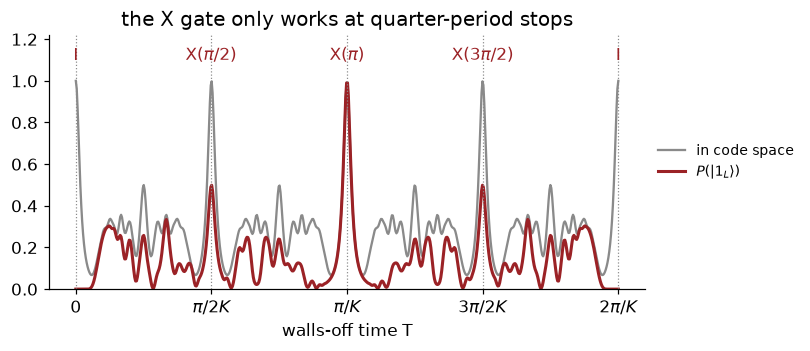

In [20]:
N, A2 = 40, 4.0
alpha = np.sqrt(A2)
n2 = np.arange(N)**2
psi0 = qt.coherent(N, alpha)
Ts = np.linspace(0, 2 * np.pi, 600)
data = []
for T in Ts:
    psi = qt.Qobj(np.exp(1j * T * n2) * psi0.full().ravel())    # e^{iKT n^2}|alpha>, K = 1
    z0, z1 = logical(N, alpha)
    data.append([abs(z0.overlap(psi))**2, abs(z1.overlap(psi))**2])
data = np.array(data)

plt.figure(figsize=(7, 3))
plt.plot(Ts, data.sum(1), color=GREY, lw=1.5, label="in code space")
plt.plot(Ts, data[:, 1], color=RED, lw=2, label=r"$P(|1_L\rangle)$")
for m, lab in enumerate(["I", r"X($\pi$/2)", r"X($\pi$)", r"X(3$\pi$/2)", "I"]):
    plt.axvline(m * np.pi / 2, color=GREY, ls=":", lw=0.8)
    plt.text(m * np.pi / 2, 1.1, lab, ha="center", color=RED)
plt.xticks([m * np.pi / 2 for m in range(5)], ["0", r"$\pi/2K$", r"$\pi/K$", r"$3\pi/2K$", r"$2\pi/K$"])
plt.xlabel("walls-off time T"); plt.ylim(0, 1.22)
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9, frameon=False)
plt.title("the X gate only works at quarter-period stops"); plt.show()

### The catch: a photon lost mid-gate

Suppose a photon escapes at time $t$ while the walls are down. Moving $\hat a$ through the Kerr evolution,
using $\hat a\, f(\hat n) = f(\hat n + 1)\,\hat a$:

$$\hat a\, e^{iKt\hat n^2} = e^{iKt(\hat n+1)^2}\,\hat a = e^{iKt\hat n^2}\;\underbrace{e^{iKt(2\hat n + 1)}}_{\text{rotation by } 2Kt}\;\hat a .$$

A lost photon adds an extra **phase-space rotation by $2Kt$**. Unless that angle is a multiple of $\pi$, the
cat refocuses in the wrong place: a harmless phase flip has turned into a bit flip (and leakage).
That is why this X gate is **not bias-preserving**.

no photon lost            : in code space 1.000,  P(|1_L>) = 1.000
photon lost at 0.3 pi/K   : in code space 0.004,  P(|1_L>) = 0.000


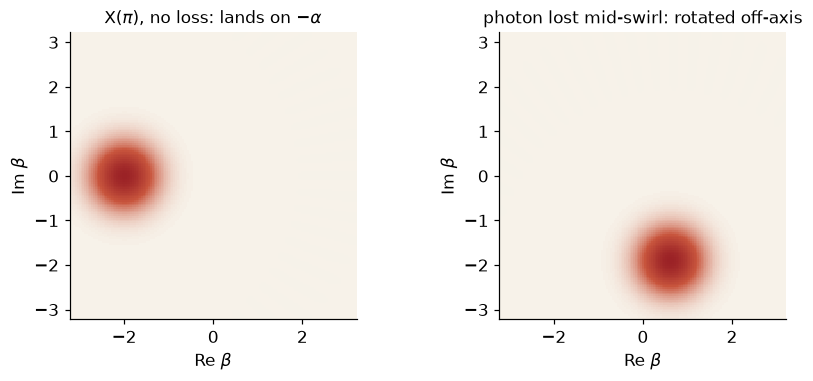

In [21]:
U = lambda T, psi: qt.Qobj(np.exp(1j * T * n2) * psi.full().ravel())
a = qt.destroy(N)
T_gate, t_jump = np.pi, 0.3 * np.pi                     # full X(pi); photon lost at 0.3 pi / K

clean = U(T_gate, psi0)
lossy = U(T_gate - t_jump, (a * U(t_jump, psi0)).unit())
for name, s in [("no photon lost", clean), ("photon lost at 0.3 pi/K", lossy)]:
    (_, _, z), pc = bloch(s, alpha)
    print(f"{name:26s}: in code space {pc:.3f},  P(|1_L>) = {(pc - z) / 2:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
plot_wigner(ax[0], clean, r"X($\pi$), no loss: lands on $-\alpha$")
plot_wigner(ax[1], lossy, r"photon lost mid-swirl: rotated off-axis")
plt.tight_layout(); plt.show()

### 🎛️ Watch it: the X gate with the walls down

The cat swirls through phase space and comes back as $|1_L\rangle$ at $t = \pi/K$. Now tick
*lose a photon* and move the loss time: the swirl ends in the wrong place, mostly outside the code space.

In [22]:
sw_N, sw_alpha = 40, 2.0
sw_a = qt.destroy(sw_N)
sw_n2 = np.arange(sw_N)**2
sw_z0, sw_z1 = logical(sw_N, sw_alpha)
kerr = lambda tt, psi: qt.Qobj(np.exp(1j * tt * sw_n2) * psi.full().ravel())     # e^{iKt n^2}, K = 1
sw_times = np.linspace(0, np.pi, 61)

def draw_swirl(k, lose, t_jump):
    t, tj = sw_times[k], t_jump * np.pi
    psi = qt.coherent(sw_N, sw_alpha)
    if lose and t > tj:
        psi = kerr(t - tj, (sw_a * kerr(tj, psi)).unit())     # swirl, lose a photon, swirl on
    else:
        psi = kerr(t, psi)
    p0, p1 = abs(sw_z0.overlap(psi))**2, abs(sw_z1.overlap(psi))**2
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
    show_wigner(ax[0], wigner_grid(psi), rf"walls down for $t = {t / np.pi:.2f}\,\pi/K$")
    ax[1].bar([r"$|0_L\rangle$", r"$|1_L\rangle$", "outside"], [p0, p1, max(1 - p0 - p1, 0)], color=[BLUE, RED, GREY])
    ax[1].set_ylim(0, 1.05); ax[1].set_ylabel("probability")
    ax[1].set_title(rf"photon lost at {t_jump:.2f}$\,\pi/K$" if lose and t > tj else "no photon lost", fontsize=10)
    plt.tight_layout(); plt.show()

glider(draw_swirl, len(sw_times),
       lose=widgets.Checkbox(value=False, description="lose a photon at", indent=False),
       t_jump=widgets.FloatSlider(value=0.3, min=0.05, max=0.95, step=0.05, description="loss time (π/K)",
                                  style={"description_width": "initial"},
                                  continuous_update=False))

Output()

## 7. Bias-Preserving X

The rotation operator $\hat R(\theta) = e^{i\theta\hat n}$ turns phase space by $\theta$:

$$e^{i\theta\hat n}|\alpha\rangle = e^{-|\alpha|^2/2}\sum_n \frac{(\alpha e^{i\theta})^n}{\sqrt{n!}}|n\rangle = |\alpha e^{i\theta}\rangle
\quad\Longrightarrow\quad
\hat R(\pi)|\alpha\rangle = |{-\alpha}\rangle,\;\; \hat R(\pi) = X_L .$$

And photon loss passes through a rotation with only a phase:

$$\hat a\, e^{i\theta\hat n} = e^{i\theta}\, e^{i\theta\hat n}\,\hat a .$$

So if we **rotate the whole landscape with the cat inside**, a lost photon at any moment stays a phase flip.
To rotate the valleys we rotate the phase of the two-photon drive:

$$\hat H(t) = -K\big(\hat a^{\dagger 2} - \alpha^2 e^{-2i\phi(t)}\big)\big(\hat a^{2} - \alpha^2 e^{2i\phi(t)}\big) \;-\; \dot\phi(t)\,\hat a^\dagger \hat a .$$

The first term has its valleys at $\pm\alpha e^{i\phi(t)}$. The second term cancels the "centrifugal" term
that appears in the frame rotating with the cat, so the cat follows the valleys **exactly, at any speed**
([Puri *et al.*, 2020](https://doi.org/10.1126/sciadv.aay5901)).

R(pi)|alpha> vs |-alpha>:  fidelity = 1.0
no loss, rotation gate: P(intended) = 1.0


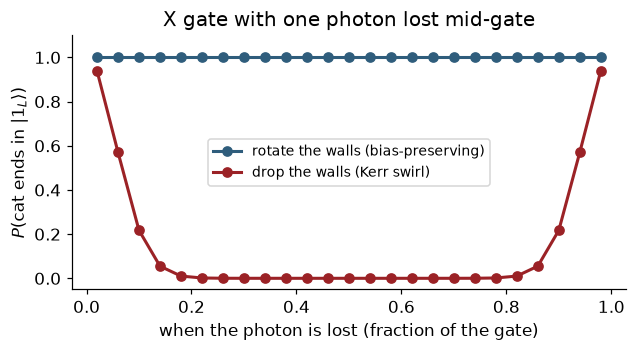

In [23]:
N, A2, T = 30, 4.0, 3.0
alpha = np.sqrt(A2)
a = qt.destroy(N)
phi = lambda t: np.pi * min(max(t / T, 0.0), 1.0)
H_rot = [-a.dag()**2 * a**2 - A2**2 * qt.qeye(N),
         [A2 * a.dag()**2, lambda t: np.exp(2j * phi(t))],
         [A2 * a**2,       lambda t: np.exp(-2j * phi(t))],
         -(np.pi / T) * a.dag() * a]

print("R(pi)|alpha> vs |-alpha>:  fidelity =",
      round(abs(qt.coherent(N, -alpha).overlap((1j * np.pi * a.dag() * a).expm() * qt.coherent(N, alpha)))**2, 6))

def rotate(psi, t0, t1):
    return qt.sesolve(H_rot, psi, [t0, t1], options=OPTS).states[-1]

def p_intended_rotation(t_jump):           # X by rotation, photon lost at t_jump
    s = rotate(qt.coherent(N, alpha), 0, t_jump)
    return abs(qt.coherent(N, -alpha).overlap(rotate((a * s).unit(), t_jump, T)))**2

def p_intended_swirl(frac):                # X by dropping the walls, photon lost at frac * pi/K
    n2 = np.arange(N)**2
    U = lambda tt, p: qt.Qobj(np.exp(1j * tt * n2) * p.full().ravel())
    s = U(np.pi - frac * np.pi, (a * U(frac * np.pi, qt.coherent(N, alpha))).unit())
    return abs(qt.coherent(N, -alpha).overlap(s))**2

fr = np.linspace(0.02, 0.98, 25)
p_rot = [p_intended_rotation(f * T) for f in fr]
p_swl = [p_intended_swirl(f) for f in fr]
print("no loss, rotation gate: P(intended) =", round(abs(qt.coherent(N, -alpha).overlap(rotate(qt.coherent(N, alpha), 0, T)))**2, 4))

plt.figure(figsize=(6.5, 3))
plt.plot(fr, p_rot, "o-", color=BLUE, lw=2, label="rotate the walls (bias-preserving)")
plt.plot(fr, p_swl, "o-", color=RED, lw=2, label="drop the walls (Kerr swirl)")
plt.xlabel("when the photon is lost (fraction of the gate)"); plt.ylabel(r"$P$(cat ends in $|1_L\rangle$)")
plt.ylim(-0.05, 1.1); plt.legend(fontsize=9); plt.title("X gate with one photon lost mid-gate"); plt.show()

With rotating walls, the cat always ends where it should, whenever the photon is lost. With dropped walls,
almost any loss moment sends it astray.

### 🎛️ Watch it: rotating the walls

We start in an unequal superposition, $\cos\frac{\pi}{8}|0_L\rangle + \sin\frac{\pi}{8}|1_L\rangle$, so the two blobs
have different weights (85% and 15%). The open circles mark the valleys $\pm\alpha e^{i\phi(t)}$. Tick
*photon lost at 0.4 T*: the fringes shift (a phase flip), but the weights do not change. No bit flip.

The bars show how much of the state sits in each *moving* valley. The weights ride along with the valleys:
at $\phi = \pi$ the valley that started at $+\alpha$ has reached $-\alpha$, so the 85% now sits in $|1_L\rangle$.

In [24]:
rot_N, rot_alpha, rot_T = N, alpha, T
rot_a = qt.destroy(rot_N)
rot_times = np.linspace(0, rot_T, 61)
rot_z0, rot_z1 = logical(rot_N, rot_alpha)
rot_n = rot_a.dag() * rot_a
psi_start = np.cos(np.pi / 8) * rot_z0 + np.sin(np.pi / 8) * rot_z1
k_jump = 24                                                     # photon lost at t = 0.4 T
clean = qt.sesolve(H_rot, psi_start, rot_times, options=OPTS).states
after = qt.sesolve(H_rot, (rot_a * clean[k_jump]).unit(), rot_times[k_jump:], options=OPTS).states
lossy = clean[:k_jump] + after

def draw_rot(k, lose):
    psi = (lossy if lose else clean)[k]
    phi_k = np.pi * rot_times[k] / rot_T
    R = (1j * phi_k * rot_n).expm()                 # the logical states, rotated along with the valleys
    p0, p1 = abs((R * rot_z0).overlap(psi))**2, abs((R * rot_z1).overlap(psi))**2
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
    show_wigner(ax[0], wigner_grid(psi), rf"valleys rotated by $\phi = {phi_k / np.pi:.2f}\,\pi$")
    v = rot_alpha * np.exp(1j * phi_k)
    ax[0].plot([v.real, -v.real], [v.imag, -v.imag], "o--", color="0.2", mfc="none", ms=16, lw=0.8)
    ax[1].bar([r"valley $+\alpha e^{i\phi}$", r"valley $-\alpha e^{i\phi}$", "outside"], [p0, p1, max(1 - p0 - p1, 0)],
              color=[BLUE, RED, GREY])
    ax[1].set_ylim(0, 1.05); ax[1].set_ylabel("probability")
    ax[1].set_title("photon lost at 0.4 T" if lose and k >= k_jump else "no photon lost", fontsize=10)
    plt.tight_layout(); plt.show()

glider(draw_rot, len(rot_times), lose=widgets.Checkbox(value=False, description="photon lost at 0.4 T", indent=False))

Output()

A **CNOT** needs exactly this rotation, but only *when the other cat says so*.

## 8. Bias-Preserving CX

The ideal bias-preserving CX rotates the target by $\pi$ only if the control is $|1_L\rangle = |{-\beta}\rangle$:

$$\hat U_\text{CX} = |\beta\rangle\langle\beta|_c \otimes \mathbb 1_t \;+\; |{-\beta}\rangle\langle{-\beta}|_c \otimes e^{i\pi \hat a_t^\dagger \hat a_t}.$$

[Puri *et al.*, 2020](https://doi.org/10.1126/sciadv.aay5901) wrote a Hamiltonian that does this. Take the
rotating-walls Hamiltonian of Section 7 and make the rotation depend on the control's field $\hat b$:

$$\hat H_\text{CX} = -K(\hat b^{\dagger 2} - \beta^2)(\hat b^{2} - \beta^2) \;-\; K\,\hat L_t^\dagger \hat L_t \;-\; \frac{\dot\phi}{4\beta}\,\hat a_t^\dagger\hat a_t\,(2\beta - \hat b - \hat b^\dagger),$$
$$\hat L_t = \hat a_t^2 - \alpha^2\Big[e^{2i\phi(t)}\,\frac{\beta - \hat b}{2\beta} + \frac{\beta + \hat b}{2\beta}\Big].$$

Check it by replacing $\hat b$ with its value in each control state:

* control $|0_L\rangle$, $\hat b \to +\beta$: $\;\hat L_t \to \hat a_t^2 - \alpha^2$ and the last term $\to 0$: the target sits still.
* control $|1_L\rangle$, $\hat b \to -\beta$: $\;\hat L_t \to \hat a_t^2 - \alpha^2 e^{2i\phi}$ and the last term $\to -\dot\phi\,\hat a_t^\dagger\hat a_t$: exactly the rotating walls of Section 7.

The hard part is building the two-mode terms in hardware (a three-wave-mixing term and a conditional
displacement). In the talk's preprint, a single **asymmetrically threaded SQUID (ATS)** coupler provides both
([Yurtseven *et al.*, 2026](https://arxiv.org/abs/2610.28749)). Here we simulate only the effective
Hamiltonian above, with $\alpha = \beta = 2$ and $T = 10/K$ as in Puri *et al.*

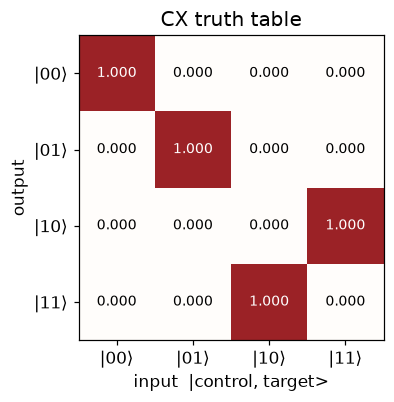

In [25]:
def build_cx(A2, B2, T, Nt=20, Nc=None):
    Nc = Nc or int(B2 + 6 * np.sqrt(B2) + 8)
    beta = np.sqrt(B2)
    at = qt.tensor(qt.destroy(Nt), qt.qeye(Nc))        # target  (first)
    b = qt.tensor(qt.qeye(Nt), qt.destroy(Nc))         # control (second)
    I = qt.qeye([Nt, Nc])
    P_plus, P_minus = (beta * I + b) / (2 * beta), (beta * I - b) / (2 * beta)
    M, Q = at**2 - A2 * P_plus, A2 * P_minus           # L_t = M - e^{2i phi} Q
    phi = lambda t: np.pi * min(max(t / T, 0.0), 1.0)
    H = [-(b.dag()**2 - B2) * (b**2 - B2) - (M.dag() * M + Q.dag() * Q),
         [M.dag() * Q, lambda t: np.exp(2j * phi(t))],
         [Q.dag() * M, lambda t: np.exp(-2j * phi(t))],
         -(np.pi / T) / (4 * beta) * at.dag() * at * (2 * beta * I - b - b.dag())]
    return H, at, b, Nt, Nc

A2, B2, T = 4.0, 4.0, 10.0
H, at, b, Nt, Nc = build_cx(A2, B2, T)
alpha, beta = np.sqrt(A2), np.sqrt(B2)
ket = lambda c, tg: qt.tensor(qt.coherent(Nt, alpha * (1 - 2 * tg)), qt.coherent(Nc, beta * (1 - 2 * c)))

table = np.zeros((4, 4))
for i, (c, tg) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1)]):
    out = qt.sesolve(H, ket(c, tg), [0, T], options=OPTS).states[-1]
    table[:, i] = [abs(ket(c2, t2).overlap(out))**2 for c2, t2 in [(0, 0), (0, 1), (1, 0), (1, 1)]]

labs = [r"$|00\rangle$", r"$|01\rangle$", r"$|10\rangle$", r"$|11\rangle$"]
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(table, cmap=LinearSegmentedColormap.from_list("t", ["#fffdfb", RED]), vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{table[i, j]:.3f}", ha="center", va="center", fontsize=9,
                color="white" if table[i, j] > 0.5 else "black")
ax.set_xticks(range(4)); ax.set_xticklabels(labs); ax.set_yticks(range(4)); ax.set_yticklabels(labs)
ax.set_xlabel("input  |control, target>"); ax.set_ylabel("output")
ax.spines[:].set_visible(True); ax.set_title("CX truth table"); plt.show()

The control decides, the target flips. Now the two tests that matter.

**Entanglement:** a control in $|+_L\rangle$ should give a Bell state.
**Bias:** a photon lost by the target *in the middle of the gate* should not flip its bit.

In [26]:
plus_c = (qt.coherent(Nc, beta) + qt.coherent(Nc, -beta)).unit()
psi_in = qt.tensor(qt.coherent(Nt, alpha), plus_c)                 # |+>_c |0>_t
bell = (ket(0, 0) + ket(1, 1)).unit()                              # (|00> + |11>)/sqrt2
out = qt.sesolve(H, psi_in, [0, T], options=OPTS).states[-1]
print(f"Bell-state fidelity: {abs(bell.overlap(out))**2:.4f}")

# control |1>, target |0>: should end in |1,1>. Lose a target photon at T/2.
s = qt.sesolve(H, ket(1, 0), [0, T / 2], options=OPTS).states[-1]
s = qt.sesolve(H, (at * s).unit(), [T / 2, T], options=OPTS).states[-1]
print(f"photon lost at T/2:  P(target bit correct) = {abs(ket(1, 1).overlap(s))**2:.4f}"
      f",  P(target bit flipped) = {abs(ket(1, 0).overlap(s))**2:.1e}")

Bell-state fidelity: 0.9998
photon lost at T/2:  P(target bit correct) = 0.9997,  P(target bit flipped) = 1.8e-06


The lost photon did not flip the target's bit: the gate preserves the noise bias.

### Exercise: why a big control cat helps

In this model the dominant error of a *fast* gate is the control cat being kicked out of its valley: the last
term of $\hat H_\text{CX}$ pushes on the control with a strength $\sim \dot\phi\,\alpha^2/\beta \sim \alpha^2/(\beta T)$, while the control's energy
gap grows as $\approx 4K\beta^2$. Their ratio, $\xi \sim \alpha^2/(\beta^3 K T)$, sets the error. A **bigger control and a smaller target** allow much faster gates, which is
the idea behind the ATS gate in the preprint. Try it:

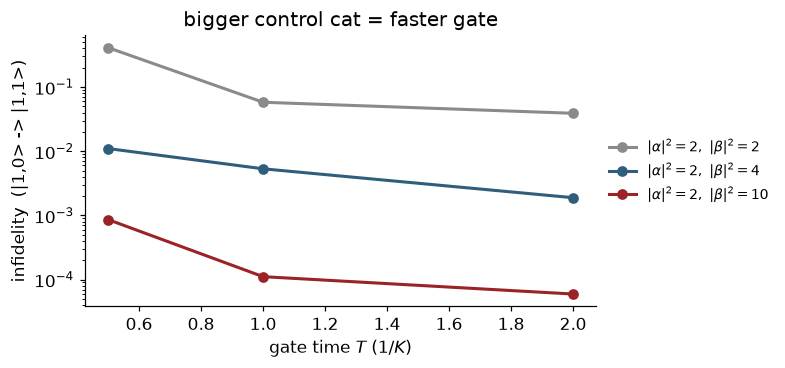

In [27]:
def cx_error(A2, B2, T):
    H, at, b, Nt, Nc = build_cx(A2, B2, T, Nt=16)
    a_, b_ = np.sqrt(A2), np.sqrt(B2)
    psi = qt.tensor(qt.coherent(Nt, a_), qt.coherent(Nc, -b_))
    out = qt.sesolve(H, psi, [0, T], options=OPTS).states[-1]
    return 1 - abs(qt.tensor(qt.coherent(Nt, -a_), qt.coherent(Nc, -b_)).overlap(out))**2

Ts = [0.5, 1.0, 2.0]
plt.figure(figsize=(6, 3.2))
for B2, col in [(2, GREY), (4, BLUE), (10, RED)]:
    plt.semilogy(Ts, [cx_error(2.0, B2, T) for T in Ts], "o-", color=col, lw=2,
                 label=rf"$|\alpha|^2 = 2,\ |\beta|^2 = {B2}$")
plt.xlabel(r"gate time $T$ ($1/K$)"); plt.ylabel("infidelity  (|1,0> -> |1,1>)")
plt.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.title("bigger control cat = faster gate"); plt.show()

### 🎛️ Watch it: the CX gate

Left: the target cat. Right: the control cat. Each panel shows that cat on its own (the partial trace).
* Control $|0_L\rangle$: nothing happens. Control $|1_L\rangle$: the target turns by $\pi$.
* Control $|+_L\rangle$: the target splits into *both* outcomes, and the fringes of **both** cats fade. Neither cat
  alone is in a pure state any more; the information is in the correlation between them. That is
  entanglement: the purity $\mathrm{Tr}\,\rho^2$ drops from 1 to ½.

In [ ]:
cx_H, _, _, cx_Nt, cx_Nc = build_cx(4.0, 4.0, 10.0)            # alpha = beta = 2,  T = 10/K
cx_al, cx_be, cx_T = 2.0, 2.0, 10.0
cx_times = np.linspace(0, cx_T, 41)
cx_controls = {"control |0_L⟩": qt.coherent(cx_Nc, cx_be), "control |1_L⟩": qt.coherent(cx_Nc, -cx_be),
               "control |+_L⟩": cat(cx_Nc, cx_be, +1)}
cx_runs = {name: qt.sesolve(cx_H, qt.tensor(qt.coherent(cx_Nt, cx_al), c), cx_times, options=OPTS).states
           for name, c in cx_controls.items()}

def draw_cx(k, control):
    psi = cx_runs[control][k]
    rho_t, rho_c = psi.ptrace(0), psi.ptrace(1)          # target is the first mode, control the second
    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    show_wigner(ax[0], wigner_grid(rho_t), rf"target,  Tr$\rho^2$ = {(rho_t * rho_t).tr().real:.2f}")
    show_wigner(ax[1], wigner_grid(rho_c), rf"control,  Tr$\rho^2$ = {(rho_c * rho_c).tr().real:.2f}")
    fig.suptitle(rf"$t = {cx_times[k]:.2f}/K$", fontsize=11)
    plt.tight_layout(); plt.show()

glider(draw_cx, len(cx_times), control=widgets.ToggleButtons(style={"button_width": "auto"}, options=list(cx_controls)))

Output()

## 9. Where to go next

**Things to try in this notebook**
* Section 3: what is the slowest ramp you need for 99% fidelity at $|\alpha|^2 = 2$ or $6$?
* Section 5: add thermal noise, `np.sqrt(k1 * nth) * a.dag()`, to the collapse operators. What happens to the bit-flip rate?
* Section 6: make $\epsilon_x$ larger. When does the Z gate start to leak out of the code space?
* Section 7: change the rotation time $T$. Does the rotating-walls gate ever fail?
* Section 8: try $T = 2/K$ with $\alpha = \beta = 2$, then $\beta^2 = 10$.

**References**
1. J. Koch *et al.*, *Charge-insensitive qubit design derived from the Cooper pair box*, [PRA 76, 042319 (2007)](https://doi.org/10.1103/PhysRevA.76.042319).
2. P. T. Cochrane, G. J. Milburn, W. J. Munro, *Macroscopically distinct quantum superposition states as a bosonic code for amplitude damping*, [PRA 59, 2631 (1999)](https://doi.org/10.1103/PhysRevA.59.2631).
3. B. Yurke, D. Stoler, *Generating quantum mechanical superpositions of macroscopically distinguishable states via amplitude dispersion*, [PRL 57, 13 (1986)](https://doi.org/10.1103/PhysRevLett.57.13).
4. M. Mirrahimi *et al.*, *Dynamically protected cat-qubits: a new paradigm for universal quantum computation*, [NJP 16, 045014 (2014)](https://doi.org/10.1088/1367-2630/16/4/045014).
5. Z. Leghtas *et al.*, *Confining the state of light to a quantum manifold by engineered two-photon loss*, [Science 347, 853 (2015)](https://doi.org/10.1126/science.aaa2085).
6. H. Goto, *Bifurcation-based adiabatic quantum computation with a nonlinear oscillator network*, [Sci. Rep. 6, 21686 (2016)](https://doi.org/10.1038/srep21686).
7. S. Puri, S. Boutin, A. Blais, *Engineering the quantum states of light in a Kerr-nonlinear resonator by two-photon driving*, [npj Quantum Inf. 3, 18 (2017)](https://doi.org/10.1038/s41534-017-0019-1).
8. J. Guillaud, M. Mirrahimi, *Repetition cat qubits for fault-tolerant quantum computation*, [PRX 9, 041053 (2019)](https://doi.org/10.1103/PhysRevX.9.041053).
9. R. Lescanne *et al.*, *Exponential suppression of bit-flips in a qubit encoded in an oscillator*, [Nat. Phys. 16, 509 (2020)](https://doi.org/10.1038/s41567-020-0824-x).
10. A. Grimm *et al.*, *Stabilization and operation of a Kerr-cat qubit*, [Nature 584, 205 (2020)](https://doi.org/10.1038/s41586-020-2587-z).
11. U. Réglade *et al.*, *Quantum control of a cat qubit with bit-flip times exceeding ten seconds*, [Nature 629, 778 (2024)](https://doi.org/10.1038/s41586-024-07294-3).
12. S. Puri *et al.*, *Bias-preserving gates with stabilized cat qubits*, [Sci. Adv. 6, eaay5901 (2020)](https://doi.org/10.1126/sciadv.aay5901).
13. A. G. Fowler *et al.*, *Surface codes: Towards practical large-scale quantum computation*, [PRA 86, 032324 (2012)](https://doi.org/10.1103/PhysRevA.86.032324).
14. Google Quantum AI and Collaborators, *Quantum error correction below the surface code threshold*, [Nature 638, 920 (2025)](https://doi.org/10.1038/s41586-024-08449-y).
15. H. Putterman *et al.*, *Hardware-efficient quantum error correction via concatenated bosonic qubits*, [Nature 638, 927 (2025)](https://doi.org/10.1038/s41586-025-08642-7).
16. K. Yurtseven *et al.*, *Bias-Preserving Entanglement of Kerr-Cat Qubits with an ATS Coupler*, [arXiv:2610.28749 (2026)](https://arxiv.org/abs/2610.28749).

*Questions or comments: keremyurtseven@tudelft.nl*

*Claude Opus 5.5 is used as an assistant in the preparation of this notebook.*